In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

tf.keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)

Количество данных: 2880
Минимальная температура: 18.205462
Максимальная температура: 28.833134


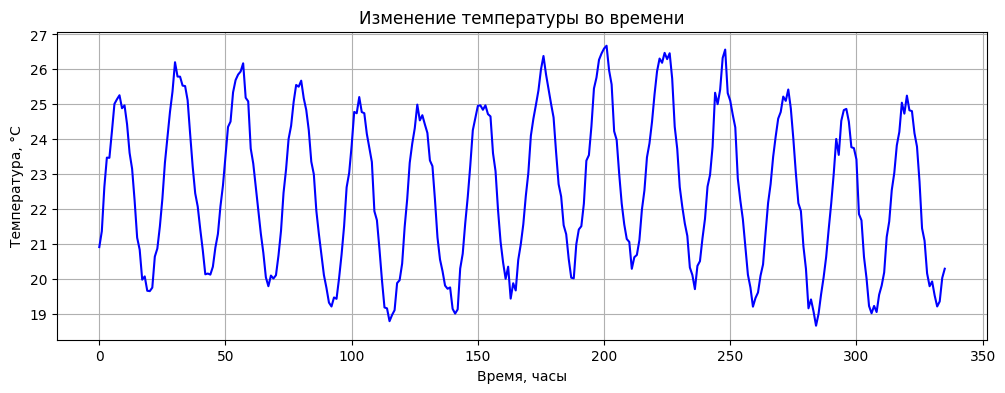

In [2]:
N = 120 * 24
t = np.arange(N)

series = (
    22
    + 3.0 * np.sin(2 * np.pi * t / 24 - 0.4)
    + 0.8 * np.sin(2 * np.pi * t / (24 * 7))
    + 0.6 * np.sin(2 * np.pi * t / (24 * 30))
    + 0.001 * t
    + rng.normal(0, 0.25, N)
).astype(np.float32)

print("Количество данных:", len(series))
print("Минимальная температура:", series.min())
print("Максимальная температура:", series.max())

plt.figure(figsize=(12, 4))
plt.plot(t[:24 * 14], series[:24 * 14], color="blue")
plt.xlabel("Время, часы")
plt.ylabel("Температура, °C")
plt.title("Изменение температуры во времени")
plt.grid(True)
plt.show()

In [3]:
train_end = int(0.70 * N)
val_end = int(0.85 * N)

print("Граница train:", train_end)
print("Граница validation:", val_end)
print("Всего данных:", N)

scaler = MinMaxScaler()
scaler.fit(series[:train_end].reshape(-1, 1))
scaled = scaler.transform(series.reshape(-1, 1))

Граница train: 2015
Граница validation: 2448
Всего данных: 2880


In [4]:
lookback = 24

X, y, target_times = [], [], []

for i in range(lookback, N):
    X.append(scaled[i - lookback:i, 0])
    y.append(scaled[i, 0])
    target_times.append(i)

X = np.asarray(X, dtype=np.float32)[..., None]
y = np.asarray(y, dtype=np.float32)
target_times = np.asarray(target_times)

train_mask = target_times < train_end
val_mask = (target_times >= train_end) & (target_times < val_end)
test_mask = target_times >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1991, 24, 1)
Validation: (433, 24, 1)
Testing: (432, 24, 1)


In [5]:
lstm_model = tf.keras.Sequential([
    tf.keras.Input(shape=(24, 1)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1)
])

lstm_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
lstm_model.summary()

tf.keras.utils.set_random_seed(42)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

start_time = time.perf_counter()

lstm_history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

lstm_time = time.perf_counter() - start_time
print("Время обучения LSTM:", lstm_time)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0611 - val_loss: 0.0321
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0151 - val_loss: 0.0132
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0044 - val_loss: 0.0152
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0036 - val_loss: 0.0072
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0027 - val_loss: 0.0049
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0023 - val_loss: 0.0042
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0020 - val_loss: 0.0038
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0018 - val_loss: 0.0035
Epoch 9/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0017 - val_loss: 0.0033
Epoch 10/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0016 - val_loss: 0.0031
Epoch 11/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 12/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0

In [6]:
gru_model = tf.keras.Sequential([
    tf.keras.Input(shape=(24, 1)),
    tf.keras.layers.GRU(32),
    tf.keras.layers.Dense(1)
])

gru_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
gru_model.summary()

tf.keras.utils.set_random_seed(42)

early_stop_gru = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

start_time = time.perf_counter()

gru_history = gru_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop_gru],
    verbose=1
)

gru_time = time.perf_counter() - start_time
print("Время обучения GRU:", gru_time)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0458 - val_loss: 0.0167
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0130 - val_loss: 0.0080
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0050 - val_loss: 0.0062
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0026 - val_loss: 0.0057
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0024 - val_loss: 0.0043
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0022 - val_loss: 0.0038
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0021 - val_loss: 0.0035
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0020 - val_loss: 0.0033
Epoch 9/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0020 - val_loss: 0.0031
Epoch 10/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0019 - val_loss: 0.0030
Epoch 11/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018 - val_loss: 0.0029
Epoch 12/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0

In [7]:
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)
gru_pred_scaled = gru_model.predict(X_test, verbose=0)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled).ravel()
gru_pred = scaler.inverse_transform(gru_pred_scaled).ravel()

actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

naive_pred = series[target_times[test_mask] - 1]

In [8]:
def calculate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    return mae, rmse

naive_mae, naive_rmse = calculate_metrics(actual, naive_pred)
lstm_mae, lstm_rmse = calculate_metrics(actual, lstm_pred)
gru_mae, gru_rmse = calculate_metrics(actual, gru_pred)

print("Naive:")
print("MAE:", naive_mae)
print("RMSE:", naive_rmse)

print("\nLSTM:")
print("MAE:", lstm_mae)
print("RMSE:", lstm_rmse)

print("\nGRU:")
print("MAE:", gru_mae)
print("RMSE:", gru_rmse)

print("\nВремя обучения:")
print("LSTM:", lstm_time, "сек")
print("GRU:", gru_time, "сек")

print("\nКоличество параметров:")
print("LSTM:", lstm_model.count_params())
print("GRU:", gru_model.count_params())

Naive:
MAE: 0.56000257
RMSE: 0.66070604

LSTM:
MAE: 0.2894529
RMSE: 0.36244527

GRU:
MAE: 0.3611305
RMSE: 0.4469082

Время обучения:
LSTM: 22.863726480000196 сек
GRU: 30.862170265999794 сек

Количество параметров:
LSTM: 4385
GRU: 3393


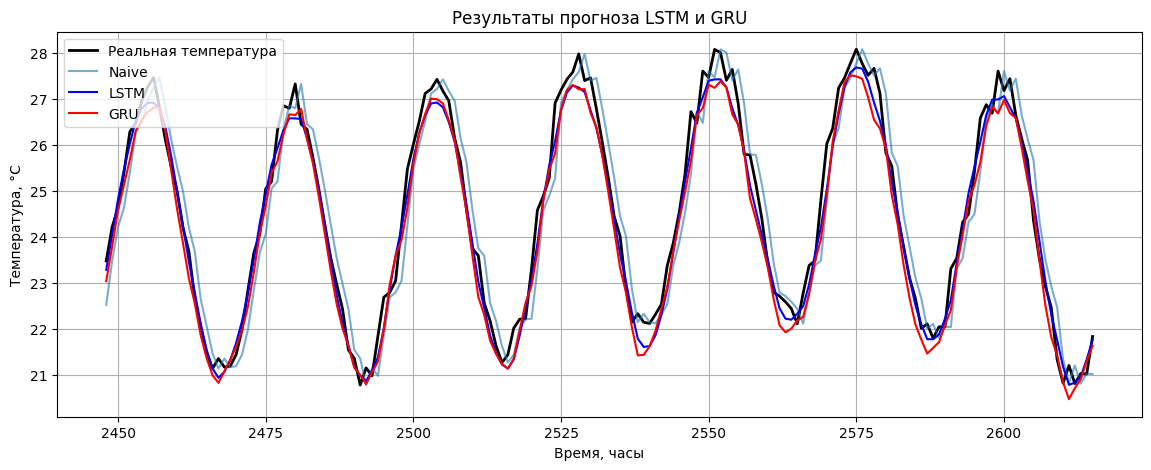

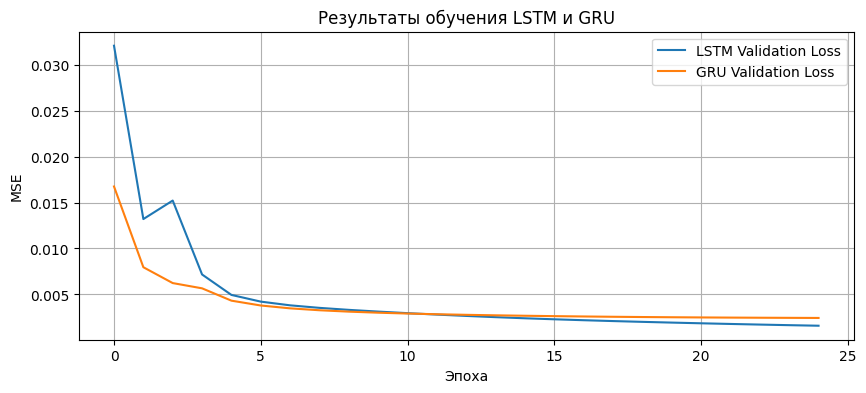

In [9]:
k = min(24 * 7, len(actual))
hours = target_times[test_mask][:k]

plt.figure(figsize=(14, 5))
plt.plot(hours, actual[:k], label="Реальная температура", color="black", linewidth=2)
plt.plot(hours, naive_pred[:k], label="Naive", alpha=0.6)
plt.plot(hours, lstm_pred[:k], label="LSTM", color="blue")
plt.plot(hours, gru_pred[:k], label="GRU", color="red")
plt.xlabel("Время, часы")
plt.ylabel("Температура, °C")
plt.title("Результаты прогноза LSTM и GRU")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(lstm_history.history["val_loss"], label="LSTM Validation Loss")
plt.plot(gru_history.history["val_loss"], label="GRU Validation Loss")
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.title("Результаты обучения LSTM и GRU")
plt.legend()
plt.grid(True)
plt.show()